# 09 — `PM3-APF`: Dual-Stage7 Forked *Asynchronous Partial-Freeze* dengan Hyperparameter Asimetris

Notebook ini mengimplementasikan arsitektur gabungan paling bersih berdasarkan evaluasi terhadap `PM3_Joint (03)` dan `PM3_Decoupled (08)`:

1. **Shared Frozen Visual Trunk (`Stage 0–6` EfficientNet-B0):** Dijalankan $1\times$ di bawah `torch.no_grad()` dengan `BatchNorm2d.eval()` sebagai ekstraktor fitur dasar bersama (0 *representation drift*).
2. **Dual-Stage7 Fork (`stage7_diag` & `stage7_comp`) + Clinical Fork (`clin_diag` & `clin_comp`):**
   - **`Branch A (Diag)`:** `stage7_diag (320-ch)` + `Dropout2d(0,10)` → proyeksi $D=96$ → `FiLM (drop 0,20)` → `Cross-Attention MIL` → `clin_diag (28→48→32)` → *Boundary-Focused Mild Focal BCE* ($\gamma=1,0$, bobot `Comp=0,65`) + 5 konsep diagnostik. Hyperparameter lebih longgar (`LR=1,5e-5 / 2e-4 / 3,5e-4`, `WD=5e-3–1,5e-2`, `mod_drop=0,15`).
   - **`Branch B (Comp)`:** `stage7_comp (320-ch)` + `Dropout2d(0,20)` → proyeksi $D=64$ → `FiLM (drop 0,28)` → **Clinical-Conditioned Gated Attention MIL** ($\tau=0,45$, Xavier init, tanpa *mean bypass*, `ent_reg=0,015`) → `clin_comp (28→32→24)` → `pos_weight=sqrt(n_unc/n_comp)` + 5 konsep keparahan. Hyperparameter lebih hati-hati (`LR=1,0e-5 / 1,5e-4 / 2,2e-4`, `WD=1,2e-2–2,5e-2`, `mod_drop=0,30`).
3. **End-to-End Coupled Hierarchical Output + 3-Fase Paralel Training Parsial (*Asynchronous Partial Freeze*):**
   - Kedua cabang belajar paralel bersama lewat `Coupled Hierarchical NLL` ($w=0,50$) dengan dua optimizer, dua cosine scheduler, dua **Model EMA (`0,98`)**, dan dua monitor *loss-guarded* independen.
   - Begitu salah satu cabang (umumnya `Comp`) mencapai puncaknya dan memicu *patience*, bobot EMA terbaik cabang tersebut di-*restore* lalu **dibekukan total** (nol *drift*, nol *overfit* epoch tinggi), sementara cabang satunya terus berlatih memperhalus batas keputusannya bersama `coupled NLL` ter-detach.


In [1]:
import copy, gc, json, math, random, sys, time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0
from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_auc_score,
)

candidates = [Path.cwd(), *Path.cwd().parents]
PM3_DIR = next(
    (p if (p / "pm3_data.py").is_file() else p / "Proposed Model 3")
    for p in candidates
    if (p / "pm3_data.py").is_file() or (p / "Proposed Model 3" / "pm3_data.py").is_file()
)
ROOT_DIR = PM3_DIR.parent
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

from pm3_data import (
    CLASS_NAMES,
    CONCEPTS_PM3,
    ClinicalPipeline,
    PM3PatientBagDataset,
    USConfig,
    build_image_cache,
    collate_patients,
    encode_pm3_concepts,
    images_by_patient,
    load_cohort,
    make_stratified_folds,
)
from pm3_model import CLASS_IDS
from pm3_train import (
    bootstrap_ci,
    calibrate_thresholds_nested_oof,
    compute_metrics,
    save_json,
    set_seed,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0), "| VRAM free/total (GiB):",
          [round(x / 1024**3, 2) for x in torch.cuda.mem_get_info()])
else:
    print("Device:", DEVICE)

RUNS_DIR = PM3_DIR / "runs"
OUT_DIR = RUNS_DIR / "09_pm3_dualstage7_apf"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SKIP_IF_DONE = True

cohort = load_cohort(ROOT_DIR / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT_DIR / "image_manifest_filtered.csv")
manifest["image_id"] = manifest["image_id"].astype(str)
manifest = manifest.loc[manifest["US_Number"].isin(cohort.index)].copy().reset_index(drop=True)
folds = make_stratified_folds(cohort, seed=1, n_splits=5)
bags_all = images_by_patient(manifest, bag_mode="all")
cache = build_image_cache(manifest, ROOT_DIR / "US_Pictures_clean", USConfig(), PM3_DIR / "cache")

print(f"Cohort: {len(cohort)} pasien | Folds: {len(folds)} | OUT_DIR: {OUT_DIR}")


GPU: NVIDIA GeForce RTX 3060 Laptop GPU | VRAM free/total (GiB): [5.0, 6.0]
Preprocessing/cache PM3: 250/1741
Preprocessing/cache PM3: 500/1741
Preprocessing/cache PM3: 750/1741
Preprocessing/cache PM3: 1000/1741
Preprocessing/cache PM3: 1250/1741
Preprocessing/cache PM3: 1500/1741
Cohort: 578 pasien | Folds: 5 | OUT_DIR: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\09_pm3_dualstage7_apf


In [2]:
# ==============================================================================
# Cell 2: Arsitektur PM3-APF Dual-Stage7 & Engine Pelatihan Asinkron 3-Fase
# ==============================================================================
DIAG_CONCEPT_IDX = [0, 1, 2, 3, 5]  # Appendix_on_US, Diameter, Target_Sign, Lymph_Nodes, Tissue_Reaction
COMP_CONCEPT_IDX = [1, 4, 5, 6, 7]  # Diameter, Wall_Layers, Tissue_Reaction, Free_Fluids, Severe_Signs


@dataclass
class APFConfig:
    epochs: int = 45
    warmup_freeze_epochs: int = 5
    scheduler_t_max: int = 35
    scheduler_eta_min: float = 1e-6
    patience_diag: int = 12
    patience_comp: int = 10
    min_freeze_epoch_diag: int = 15
    min_freeze_epoch_comp: int = 12
    batch_size: int = 16
    seed: int = 1
    amp_fp16: bool = True
    bag_view_drop_prob: float = 0.25
    ema_decay: float = 0.98
    ema_start_epoch: int = 3
    loss_guard_penalty: float = 0.12
    w_diag: float = 1.0
    w_comp: float = 1.0
    w_hier_nll: float = 0.50
    hier_label_smoothing: float = 0.03

    # Branch A (Diag) — balanced, focus on No vs Unc boundary
    diag_dim: int = 96
    diag_clin_hidden: int = 48
    diag_clin_dim: int = 32
    diag_vis_proj_dim: int = 32
    diag_drop2d: float = 0.10
    diag_img_drop: float = 0.35
    diag_clin_drop: float = 0.25
    diag_film_drop: float = 0.20
    diag_head_drop: float = 0.20
    diag_attn_drop: float = 0.10
    diag_attn_temp: float = 0.65
    diag_mod_drop: float = 0.15
    diag_tab_jitter: float = 0.04
    diag_vis_jitter: float = 0.03
    diag_smoothing: float = 0.03
    diag_focal_gamma: float = 1.0
    diag_lr_bb: float = 1.5e-5
    diag_lr_attn: float = 2.0e-4
    diag_lr_head: float = 3.5e-4
    diag_wd_bb: float = 8e-3
    diag_wd_attn: float = 5e-3
    diag_wd_clin: float = 1.5e-2
    diag_wd_head: float = 5e-3
    w_aux_diag: float = 0.45
    w_concept_diag: float = 0.35

    # Branch B (Comp) — imbalanced minority (~77 pos/fold), selective Gated MIL
    comp_dim: int = 64
    comp_clin_hidden: int = 32
    comp_clin_dim: int = 24
    comp_vis_proj_dim: int = 24
    comp_drop2d: float = 0.20
    comp_img_drop: float = 0.42
    comp_clin_drop: float = 0.35
    comp_film_drop: float = 0.28
    comp_head_drop: float = 0.28
    comp_attn_drop: float = 0.15
    comp_attn_temp: float = 0.45
    comp_mod_drop: float = 0.30
    comp_tab_jitter: float = 0.06
    comp_vis_jitter: float = 0.04
    comp_smoothing: float = 0.04
    comp_entropy_reg: float = 0.015
    comp_lr_bb: float = 1.0e-5
    comp_lr_attn: float = 1.5e-4
    comp_lr_head: float = 2.2e-4
    comp_wd_bb: float = 2.0e-2
    comp_wd_attn: float = 1.2e-2
    comp_wd_clin: float = 2.5e-2
    comp_wd_head: float = 1.5e-2
    w_aux_comp: float = 0.55
    w_concept_comp: float = 0.35


class RegularizedResidualFiLM(nn.Module):
    def __init__(self, cond_dim: int, feat_dim: int, hidden: int = 32, dropout: float = 0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cond_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 2 * feat_dim),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, feat: torch.Tensor, cond: torch.Tensor):
        params = self.net(cond)
        dg, beta = params.chunk(2, dim=-1)
        if feat.dim() == 2 and dg.dim() == 1:
            dg_b, beta_b = dg.unsqueeze(0), beta.unsqueeze(0)
        else:
            dg_b, beta_b = dg, beta
        return (1.0 + dg_b) * feat + beta_b, dg, beta


class CompactClinicalEncoder(nn.Module):
    def __init__(self, in_dim: int = 28, hidden: int = 48, out_dim: int = 32, dropout: float = 0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x.float())


class CompactCrossAttentionMIL(nn.Module):
    def __init__(self, dim: int = 96, num_heads: int = 4, temperature: float = 0.65,
                 dropout: float = 0.10, clinical_dim: int = 32):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = math.sqrt(self.head_dim) * temperature

        self.q_proj = nn.Linear(dim, dim, bias=False)
        self.k_proj = nn.Linear(dim, dim, bias=False)
        self.v_proj = nn.Linear(dim, dim, bias=False)
        self.out_proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(dim)

        self.q_base = nn.Parameter(torch.randn(dim) * 0.03)
        self.q_clin = nn.Linear(clinical_dim, dim)
        nn.init.zeros_(self.q_clin.weight)
        nn.init.zeros_(self.q_clin.bias)

    def forward(self, h: torch.Tensor, e_clin: Optional[torch.Tensor] = None,
                uniform_override: bool = False):
        k_len = h.shape[0]
        if uniform_override:
            w = torch.full((k_len,), 1.0 / k_len, device=h.device, dtype=torch.float32)
            return h.float().mean(dim=0), w

        q_vec = self.q_base + (self.q_clin(e_clin) if e_clin is not None else 0.0)
        q = self.q_proj(q_vec).view(self.num_heads, 1, self.head_dim)
        k = self.k_proj(h).view(k_len, self.num_heads, self.head_dim).transpose(0, 1)
        v = self.v_proj(h).view(k_len, self.num_heads, self.head_dim).transpose(0, 1)
        scores = torch.matmul(q.float(), k.float().transpose(-2, -1)).squeeze(1) / self.scale
        w_heads = F.softmax(scores, dim=-1)
        w_drop = self.attn_drop(w_heads)
        ctx = torch.matmul(w_drop.unsqueeze(1), v.float()).squeeze(1).reshape(self.dim)
        w_mean = w_heads.mean(dim=0)
        res = (w_mean[:, None] * h.float()).sum(dim=0)
        return self.norm(self.out_proj(ctx) + res), w_mean


class ClinicalGatedAttentionMIL(nn.Module):
    # Clinical-conditioned Gated Attention MIL (Ilse et al. 2018) without uniform residual bypass
    def __init__(self, dim: int = 64, hidden: int = 32, clinical_dim: int = 24,
                 temperature: float = 0.45, dropout: float = 0.15):
        super().__init__()
        self.temperature = temperature
        self.h_norm = nn.LayerNorm(dim)
        self.V = nn.Linear(dim, hidden, bias=True)
        self.U = nn.Linear(dim, hidden, bias=True)
        self.W_c = nn.Linear(clinical_dim, hidden, bias=False)
        self.w = nn.Linear(hidden, 1, bias=False)
        self.drop = nn.Dropout(dropout)
        self.out_norm = nn.LayerNorm(dim)
        for layer in (self.V, self.U, self.W_c, self.w):
            nn.init.xavier_uniform_(layer.weight)
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

    def forward(self, h: torch.Tensor, e_clin: Optional[torch.Tensor] = None,
                uniform_override: bool = False):
        k_len = h.shape[0]
        if uniform_override:
            weights = torch.full((k_len,), 1.0 / k_len, device=h.device, dtype=torch.float32)
            return self.out_norm(h.float().mean(dim=0)), weights

        hn = self.h_norm(h.float())
        clin_term = self.W_c(e_clin.float()).unsqueeze(0) if e_clin is not None else 0.0
        u = torch.tanh(self.V(hn) + clin_term)
        g = torch.sigmoid(self.U(hn))
        scores = self.w(self.drop(u * g)).squeeze(-1) / self.temperature
        weights = F.softmax(scores, dim=0)
        z = (weights[:, None] * h.float()).sum(dim=0)
        return self.out_norm(z), weights


class BranchHeadStream(nn.Module):
    # Independent task branch starting right after Stage 7 MBConv6+SE
    def __init__(self, branch_type: str, stage7_module: nn.Module, cfg: APFConfig):
        super().__init__()
        self.branch_type = branch_type
        self.stage7 = stage7_module
        self._stage7_frozen = False
        self._branch_frozen = False

        if branch_type == "diag":
            d = cfg.diag_dim
            c_h, c_d, v_d = cfg.diag_clin_hidden, cfg.diag_clin_dim, cfg.diag_vis_proj_dim
            self.drop2d = nn.Dropout2d(cfg.diag_drop2d)
            self.img_proj = nn.Sequential(
                nn.Linear(320, d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(cfg.diag_img_drop)
            )
            self.agg = CompactCrossAttentionMIL(
                dim=d, num_heads=4, temperature=cfg.diag_attn_temp,
                dropout=cfg.diag_attn_drop, clinical_dim=c_d,
            )
            self.clin_mlp = CompactClinicalEncoder(28, c_h, c_d, cfg.diag_clin_drop)
            self.clin_skip = nn.Linear(28, 1)
            self.inst_film = RegularizedResidualFiLM(c_d, d, hidden=48, dropout=cfg.diag_film_drop)
            self.bag_film = RegularizedResidualFiLM(c_d, d, hidden=48, dropout=cfg.diag_film_drop)
            self.vis_anchor = nn.Sequential(nn.Linear(d, v_d), nn.LayerNorm(v_d), nn.GELU())
            self.head = nn.Sequential(nn.Dropout(cfg.diag_head_drop), nn.Linear(c_d + v_d, 1))
            self.concept_head = nn.Linear(d, len(DIAG_CONCEPT_IDX))
            self.aux_img_head = nn.Linear(d, 1)
            self.mod_drop = cfg.diag_mod_drop
            self.tab_jitter = cfg.diag_tab_jitter
            self.vis_jitter = cfg.diag_vis_jitter
        else:
            d = cfg.comp_dim
            c_h, c_d, v_d = cfg.comp_clin_hidden, cfg.comp_clin_dim, cfg.comp_vis_proj_dim
            self.drop2d = nn.Dropout2d(cfg.comp_drop2d)
            self.img_proj = nn.Sequential(
                nn.Linear(320, d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(cfg.comp_img_drop)
            )
            self.agg = ClinicalGatedAttentionMIL(
                dim=d, hidden=32, clinical_dim=c_d,
                temperature=cfg.comp_attn_temp, dropout=cfg.comp_attn_drop,
            )
            self.clin_mlp = CompactClinicalEncoder(28, c_h, c_d, cfg.comp_clin_drop)
            self.clin_skip = nn.Linear(28, 1)
            self.inst_film = RegularizedResidualFiLM(c_d, d, hidden=32, dropout=cfg.comp_film_drop)
            self.bag_film = RegularizedResidualFiLM(c_d, d, hidden=32, dropout=cfg.comp_film_drop)
            self.vis_anchor = nn.Sequential(nn.Linear(d, v_d), nn.LayerNorm(v_d), nn.GELU())
            self.head = nn.Sequential(nn.Dropout(cfg.comp_head_drop), nn.Linear(c_d + v_d, 1))
            self.concept_head = nn.Linear(d, len(COMP_CONCEPT_IDX))
            self.aux_img_head = nn.Linear(d, 1)
            self.mod_drop = cfg.comp_mod_drop
            self.tab_jitter = cfg.comp_tab_jitter
            self.vis_jitter = cfg.comp_vis_jitter

    def set_stage7_frozen(self, frozen: bool):
        self._stage7_frozen = bool(frozen)
        self.stage7.requires_grad_(not (self._stage7_frozen or self._branch_frozen))

    def freeze_entire_branch(self):
        self._branch_frozen = True
        self._stage7_frozen = True
        self.requires_grad_(False)
        self.eval()

    def encode_from_f6(self, f6: torch.Tensor, masks: torch.Tensor) -> torch.Tensor:
        if self._stage7_frozen or self._branch_frozen:
            with torch.no_grad():
                x = self.stage7(f6)
        else:
            x = self.stage7(f6)
        x = x.float()
        if self.training and not self._branch_frozen:
            x = self.drop2d(x)
        m = F.adaptive_avg_pool2d(masks.float(), x.shape[-2:])
        denom = m.sum((2, 3)).clamp_min(1e-6)
        pooled = (x * m).sum((2, 3)) / denom
        if self._branch_frozen:
            with torch.no_grad():
                return self.img_proj(pooled)
        return self.img_proj(pooled)

    def forward_bag(self, h_raw: torch.Tensor, tabular: torch.Tensor, uniform_override: bool = False) -> dict:
        ctx = torch.no_grad() if self._branch_frozen else torch.enable_grad()
        with ctx:
            collect = not self.training
            tab_f = tabular.float()
            if self.training and not self._branch_frozen and self.tab_jitter > 0:
                tab_f = tab_f + torch.randn_like(tab_f) * self.tab_jitter
            if self.training and not self._branch_frozen and self.vis_jitter > 0:
                h_raw = h_raw + torch.randn_like(h_raw) * self.vis_jitter

            e_clin = self.clin_mlp(tab_f)
            tab_skip = tab_f
            if self.training and not self._branch_frozen and self.mod_drop > 0:
                keep = (torch.rand((), device=e_clin.device) >= self.mod_drop).float()
                scale = 1.0 / (1.0 - self.mod_drop)
                e_clin = e_clin * keep * scale
                tab_skip = tab_skip * keep * scale

            z_raw, _ = self.agg(h_raw, None, uniform_override=uniform_override)
            concept_logits = self.concept_head(z_raw).float()
            aux_img_logit = self.aux_img_head(z_raw).float().squeeze()

            h_main, dg_inst, _ = self.inst_film(h_raw, e_clin)
            z_vis, attn_main = self.agg(h_main, e_clin, uniform_override=uniform_override)
            z_mod, dg_bag, _ = self.bag_film(z_vis, e_clin)
            fused = torch.cat([e_clin, self.vis_anchor(z_mod)], dim=-1)
            logit = self.head(fused).float().squeeze() + self.clin_skip(tab_skip).float().squeeze()

            stats = {}
            if collect:
                stats["inst_dg_l2"] = float(dg_inst.detach().norm())
                stats["bag_dg_l2"] = float(dg_bag.detach().norm())

            return {
                "logit": logit,
                "prob": logit.sigmoid(),
                "aux_img_logit": aux_img_logit,
                "concept_logits": concept_logits,
                "attention": attn_main,
                "stats": stats,
            }

    def parameter_groups(self, cfg: APFConfig) -> List[dict]:
        if self.branch_type == "diag":
            lr_bb, lr_at, lr_hd = cfg.diag_lr_bb, cfg.diag_lr_attn, cfg.diag_lr_head
            wd_bb, wd_at, wd_cl, wd_hd = cfg.diag_wd_bb, cfg.diag_wd_attn, cfg.diag_wd_clin, cfg.diag_wd_head
        else:
            lr_bb, lr_at, lr_hd = cfg.comp_lr_bb, cfg.comp_lr_attn, cfg.comp_lr_head
            wd_bb, wd_at, wd_cl, wd_hd = cfg.comp_wd_bb, cfg.comp_wd_attn, cfg.comp_wd_clin, cfg.comp_wd_head

        bb = list(self.stage7.parameters())
        bb_ids = {id(p) for p in bb}
        at = [p for m in (self.img_proj, self.agg, self.concept_head) for p in m.parameters() if id(p) not in bb_ids]
        at_ids = {id(p) for p in at}
        cl = [p for m in (self.clin_mlp, self.clin_skip) for p in m.parameters() if id(p) not in (bb_ids | at_ids)]
        used = bb_ids | at_ids | {id(p) for p in cl}
        hd = [p for p in self.parameters() if id(p) not in used]
        return [
            {"name": "stage7", "params": bb, "lr": lr_bb, "weight_decay": wd_bb},
            {"name": "attn_concept", "params": at, "lr": lr_at, "weight_decay": wd_at},
            {"name": "clinical", "params": cl, "lr": lr_hd, "weight_decay": wd_cl},
            {"name": "film_head", "params": hd, "lr": lr_hd, "weight_decay": wd_hd},
        ]


class PM3DualStage7APF(nn.Module):
    def __init__(self, cfg: APFConfig):
        super().__init__()
        self.cfg = cfg
        net = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.frozen = net.features[:7]
        self.frozen.requires_grad_(False)
        self.frozen.eval()

        self.branch_diag = BranchHeadStream("diag", copy.deepcopy(net.features[7]), cfg)
        self.branch_comp = BranchHeadStream("comp", copy.deepcopy(net.features[7]), cfg)

    def train(self, mode: bool = True):
        super().train(mode)
        self.frozen.eval()
        # Keep frozen branch strictly in eval() and ALL BatchNorm2d locked in eval()
        if self.branch_diag._branch_frozen:
            self.branch_diag.eval()
        if self.branch_comp._branch_frozen:
            self.branch_comp.eval()
        for m in self.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
        return self

    def set_stage7_frozen(self, frozen: bool):
        self.branch_diag.set_stage7_frozen(frozen)
        self.branch_comp.set_stage7_frozen(frozen)

    def encode_both_chunked(self, images: torch.Tensor, pixel_masks: torch.Tensor, pad_to_microbatch: bool = False):
        step = 16
        n_orig = len(images)
        if pad_to_microbatch and (n_orig % step != 0):
            pad_n = step - (n_orig % step)
            images = torch.cat((images, images.new_zeros((pad_n, *images.shape[1:]))), dim=0)
            pixel_masks = torch.cat((pixel_masks, pixel_masks.new_ones((pad_n, *pixel_masks.shape[1:]))), dim=0)

        h_diag_parts, h_comp_parts = [], []
        for start in range(0, len(images), step):
            im_c = images[start:start + step]
            mk_c = pixel_masks[start:start + step]
            with torch.no_grad():
                f6 = self.frozen(im_c)
            h_diag_parts.append(self.branch_diag.encode_from_f6(f6, mk_c))
            h_comp_parts.append(self.branch_comp.encode_from_f6(f6, mk_c))
        return torch.cat(h_diag_parts, dim=0)[:n_orig], torch.cat(h_comp_parts, dim=0)[:n_orig]


class BranchEMA:
    def __init__(self, branch: nn.Module, decay: float = 0.98):
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in branch.state_dict().items()}

    @torch.no_grad()
    def update(self, branch: nn.Module):
        for k, v in branch.state_dict().items():
            if v.is_floating_point():
                self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1.0 - self.decay)
            else:
                self.shadow[k].copy_(v.detach())

    def apply_to(self, branch: nn.Module) -> dict:
        cur = branch.state_dict()
        backup = {k: cur[k].detach().clone() for k in self.shadow}
        branch.load_state_dict({**cur, **self.shadow}, strict=True)
        return backup

    def restore(self, branch: nn.Module, backup: dict):
        cur = branch.state_dict()
        branch.load_state_dict({**cur, **backup}, strict=True)


def compute_apf_weights(train_df: pd.DataFrame) -> dict:
    labels = train_df["label"].to_numpy(int)
    counts = np.bincount(labels, minlength=3)
    n_tot = float(len(labels))
    # Mild boundary focus for Diag branch: No=1.0, Unc=1.12, Comp=0.65 (equal No vs App total mass)
    raw = np.array([1.0, 1.12, 0.65], dtype=float)
    target_mass = 0.5 * n_tot
    w_no = raw[0] * (target_mass / (counts[0] * raw[0]))
    w_unc = raw[1] * (target_mass / (counts[1] * raw[1] + counts[2] * raw[2]))
    w_comp = raw[2] * (target_mass / (counts[1] * raw[1] + counts[2] * raw[2]))

    pw_comp = float(np.sqrt(counts[1] / max(counts[2], 1)))
    raw_w3 = np.sqrt(n_tot / (3.0 * counts.astype(float)))
    w3 = (raw_w3 / raw_w3.mean()).tolist()

    _, c_bin, c_msk = encode_pm3_concepts(train_df, unrecorded_smoothing=0.05)
    pos = (c_bin * c_msk).sum(0)
    neg = ((1.0 - c_bin) * c_msk).sum(0)
    c_w = np.clip(np.divide(neg, pos, out=np.ones_like(pos), where=(pos > 0) & (neg > 0)), 0.5, 4.0)
    return {
        "counts": counts.tolist(),
        "diag_class_weights": [float(w_no), float(w_unc), float(w_comp)],
        "comp_pos_weight": pw_comp,
        "class_weight_3": w3,
        "concept_pos_weight": c_w.tolist(),
    }


def diag_focal_bce(logit: torch.Tensor, raw_lbl: int, weights: dict, smoothing: float, gamma: float) -> torch.Tensor:
    y = 1.0 if raw_lbl > 0 else 0.0
    ys = y * (1.0 - smoothing) + 0.5 * smoothing
    bce = F.binary_cross_entropy_with_logits(
        logit.float().view(()), torch.tensor(ys, device=logit.device, dtype=torch.float32), reduction="none"
    )
    p = logit.float().sigmoid()
    pt = p if y > 0.5 else (1.0 - p)
    focal = (1.0 - pt.clamp(1e-5, 1.0 - 1e-5)) ** gamma
    return float(weights["diag_class_weights"][raw_lbl]) * focal * bce


def comp_smoothed_bce(logit: torch.Tensor, raw_lbl: int, pos_weight: float, smoothing: float) -> torch.Tensor:
    y = 1.0 if raw_lbl == 2 else 0.0
    ys = y * (1.0 - smoothing) + 0.5 * smoothing
    pw = torch.tensor([pos_weight], device=logit.device, dtype=torch.float32)
    return F.binary_cross_entropy_with_logits(
        logit.float().view(-1), torch.tensor([ys], device=logit.device, dtype=torch.float32),
        pos_weight=pw, reduction="sum",
    )


def has_live_grads(opt: torch.optim.Optimizer) -> bool:
    return any(p.grad is not None for g in opt.param_groups for p in g["params"])


@torch.inference_mode()
def eval_apf(model: PM3DualStage7APF, loader: DataLoader, weights: dict, cfg: APFConfig,
             device: torch.device, uniform_comp_override: bool = False):
    model.eval()
    amp = cfg.amp_fp16 and device.type == "cuda"
    pw_d = torch.tensor([weights["concept_pos_weight"][k] for k in DIAG_CONCEPT_IDX], device=device, dtype=torch.float32)
    pw_c = torch.tensor([weights["concept_pos_weight"][k] for k in COMP_CONCEPT_IDX], device=device, dtype=torch.float32)

    l_diag_s, l_comp_s, l_hier_s = 0.0, 0.0, 0.0
    n_p, n_app = 0, 0
    rows = []
    for items in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            lengths = [len(it["images"]) for it in items]
            all_imgs = torch.cat([it["images"] for it in items], dim=0).to(device)
            all_msks = torch.cat([it["pixel_masks"] for it in items], dim=0).to(device)
            hd_all, hc_all = model.encode_both_chunked(all_imgs, all_msks, pad_to_microbatch=True)
            hd_splits = torch.split(hd_all, lengths, dim=0)
            hc_splits = torch.split(hc_all, lengths, dim=0)

            for item, h_d, h_c in zip(items, hd_splits, hc_splits):
                tab_i = item["tabular"].to(device)
                out_d = model.branch_diag.forward_bag(h_d, tab_i, uniform_override=False)
                out_c = model.branch_comp.forward_bag(h_c, tab_i, uniform_override=uniform_comp_override)
                lbl = int(item["label"])

                ld = diag_focal_bce(out_d["logit"], lbl, weights, cfg.diag_smoothing, cfg.diag_focal_gamma)
                lc = comp_smoothed_bce(out_c["logit"], lbl, weights["comp_pos_weight"], cfg.comp_smoothing) if lbl > 0 else torch.tensor(0.0, device=device)

                log_p0 = F.logsigmoid(-out_d["logit"].float())
                log_p1 = F.logsigmoid(out_d["logit"].float()) + F.logsigmoid(-out_c["logit"].float())
                log_p2 = F.logsigmoid(out_d["logit"].float()) + F.logsigmoid(out_c["logit"].float())
                lp = torch.stack((log_p0, log_p1, log_p2))
                eps = cfg.hier_label_smoothing
                lh = weights["class_weight_3"][lbl] * (-(1.0 - eps) * lp[lbl] - eps * lp.mean())

                l_diag_s += float(ld)
                l_comp_s += float(lc)
                l_hier_s += float(lh)
                n_p += 1
                if lbl > 0:
                    n_app += 1

                pd_v = float(out_d["prob"])
                qc_v = float(out_c["prob"])
                p0, p1, p2 = 1.0 - pd_v, pd_v * (1.0 - qc_v), pd_v * qc_v
                pred_3 = 0 if pd_v < 0.5 else (1 if qc_v < 0.5 else 2)

                ad = out_d["attention"].detach().float().cpu().numpy()
                ac = out_c["attention"].detach().float().cpu().numpy()
                k_len = len(ad)
                ent_d = float(-(ad * np.log(np.clip(ad, 1e-7, 1.0))).sum()) / np.log(k_len) if k_len > 1 else np.nan
                ent_c = float(-(ac * np.log(np.clip(ac, 1e-7, 1.0))).sum()) / np.log(k_len) if k_len > 1 else np.nan
                spr_d = float(ad.max() - ad.min()) if k_len > 1 else np.nan
                spr_c = float(ac.max() - ac.min()) if k_len > 1 else np.nan

                row = {
                    "patient_id": int(item["patient_id"]),
                    "raw_label": lbl,
                    "label": lbl,
                    "n_images": k_len,
                    "p_diag": pd_v,
                    "q_comp": qc_v,
                    "p_0": p0,
                    "p_1": p1,
                    "p_2": p2,
                    "pred": pred_3,
                    "ent_norm_diag": ent_d,
                    "ent_norm_comp": ent_c,
                    "spread_diag": spr_d,
                    "spread_comp": spr_c,
                    "diag_inst_dg": out_d["stats"].get("inst_dg_l2", np.nan),
                    "diag_bag_dg": out_d["stats"].get("bag_dg_l2", np.nan),
                    "comp_inst_dg": out_c["stats"].get("inst_dg_l2", np.nan),
                    "comp_bag_dg": out_c["stats"].get("bag_dg_l2", np.nan),
                }
                cd_p = out_d["concept_logits"].sigmoid().cpu().numpy()
                cc_p = out_c["concept_logits"].sigmoid().cpu().numpy()
                c_map = {ci: float(cd_p[j]) for j, ci in enumerate(DIAG_CONCEPT_IDX)}
                for j, ci in enumerate(COMP_CONCEPT_IDX):
                    c_map[ci] = 0.5 * (c_map[ci] + float(cc_p[j])) if ci in c_map else float(cc_p[j])
                for ci, cn in enumerate(CONCEPTS_PM3):
                    row[f"concept_p_{cn}"] = c_map[ci]
                    row[f"concept_y_{cn}"] = float(item["concepts_binary"][ci])
                    row[f"concept_mask_{cn}"] = float(item["concept_mask"][ci])
                rows.append(row)

    df = pd.DataFrame(rows)
    y3 = df["label"].to_numpy(int)
    p3 = df[["p_0", "p_1", "p_2"]].to_numpy(float)
    m3 = compute_metrics(y3, p3, df["pred"].to_numpy(int), "hierarchical")

    auc_diag = float(roc_auc_score((y3 > 0).astype(int), df["p_diag"]))
    sub01 = df[df["label"].isin([0, 1])]
    auc_0v1 = float(roc_auc_score(sub01["label"], sub01["p_diag"]))
    sub_app = df[df["label"] > 0]
    y_comp_app = (sub_app["label"] == 2).astype(int)
    auc_comp_app = float(roc_auc_score(y_comp_app, sub_app["q_comp"]))
    rec_comp_05 = float(recall_score(y_comp_app, (sub_app["q_comp"] >= 0.5).astype(int), zero_division=0))

    c_aucs = []
    for cn in CONCEPTS_PM3:
        sub = df[df[f"concept_mask_{cn}"] == 1]
        if len(sub) and sub[f"concept_y_{cn}"].nunique() == 2:
            c_aucs.append(float(roc_auc_score(sub[f"concept_y_{cn}"], sub[f"concept_p_{cn}"])))

    metrics = {
        "loss_diag": l_diag_s / max(n_p, 1),
        "loss_comp": l_comp_s / max(n_app, 1),
        "loss_hier_nll": l_hier_s / max(n_p, 1),
        "loss_total_sum": (l_diag_s / max(n_p, 1)) + (l_comp_s / max(n_app, 1)) + cfg.w_hier_nll * (l_hier_s / max(n_p, 1)),
        "auroc_3class": m3["multiclass_auroc"],
        "aupr_3class": m3["macro_aupr"],
        "acc_3class_05": m3["accuracy"],
        "mf1_3class_05": m3["macro_f1"],
        "comp_rec_3class_05": m3["complication_recall"],
        "auroc_diag": auc_diag,
        "auc_0_vs_1": auc_0v1,
        "auroc_comp_app": auc_comp_app,
        "comp_rec_app_05": rec_comp_05,
        "concept_mean_auroc": float(np.mean(c_aucs)) if c_aucs else float("nan"),
        "ent_norm_diag": float(df["ent_norm_diag"].mean()),
        "ent_norm_comp": float(df["ent_norm_comp"].mean()),
        "spread_diag": float(df["spread_diag"].mean()),
        "spread_comp": float(df["spread_comp"].mean()),
        "spread_comp_p90": float(df["spread_comp"].dropna().quantile(0.90)) if df["spread_comp"].notna().any() else float("nan"),
    }
    return metrics, df


def train_apf_fold(cfg: APFConfig, fold: dict, fold_dir: Path, device: torch.device):
    fold_dir.mkdir(parents=True, exist_ok=True)
    seed = cfg.seed + fold["fold"]
    set_seed(seed)
    tr_df = cohort.loc[fold["train"]]
    clin = ClinicalPipeline().fit(tr_df)
    weights = compute_apf_weights(tr_df)

    ds_tr = PM3PatientBagDataset(list(fold["train"]), cohort, clin, bags_all, cache, train=True, include_images=True)
    ds_va = PM3PatientBagDataset(list(fold["val"]), cohort, clin, bags_all, cache, train=False, include_images=True)
    tr_loader = DataLoader(ds_tr, batch_size=cfg.batch_size, shuffle=True, num_workers=0,
                           collate_fn=collate_patients, generator=torch.Generator().manual_seed(seed))
    va_loader = DataLoader(ds_va, batch_size=cfg.batch_size, shuffle=False, num_workers=0, collate_fn=collate_patients)

    model = PM3DualStage7APF(cfg).to(device)
    if cfg.warmup_freeze_epochs > 0:
        model.set_stage7_frozen(True)

    opt_diag = torch.optim.AdamW(model.branch_diag.parameter_groups(cfg))
    opt_comp = torch.optim.AdamW(model.branch_comp.parameter_groups(cfg))
    sch_diag = torch.optim.lr_scheduler.CosineAnnealingLR(opt_diag, T_max=cfg.scheduler_t_max, eta_min=cfg.scheduler_eta_min)
    sch_comp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_comp, T_max=cfg.scheduler_t_max, eta_min=cfg.scheduler_eta_min)

    ema_diag = BranchEMA(model.branch_diag, decay=cfg.ema_decay)
    ema_comp = BranchEMA(model.branch_comp, decay=cfg.ema_decay)

    amp = cfg.amp_fp16 and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    pw_d = torch.tensor([weights["concept_pos_weight"][k] for k in DIAG_CONCEPT_IDX], device=device, dtype=torch.float32)
    pw_c = torch.tensor([weights["concept_pos_weight"][k] for k in COMP_CONCEPT_IDX], device=device, dtype=torch.float32)

    diag_frozen, comp_frozen = False, False
    diag_freeze_ep, comp_freeze_ep = None, None
    best_diag_score, best_diag_ep, no_imp_diag, min_val_ld = -float("inf"), 0, 0, float("inf")
    best_comp_score, best_comp_ep, no_imp_comp, min_val_lc = -float("inf"), 0, 0, float("inf")
    best_diag_state = {k: v.detach().cpu().clone() for k, v in model.branch_diag.state_dict().items()}
    best_comp_state = {k: v.detach().cpu().clone() for k, v in model.branch_comp.state_dict().items()}

    rng = np.random.default_rng(seed)
    history = []

    for epoch in range(1, cfg.epochs + 1):
        if cfg.warmup_freeze_epochs > 0 and epoch == cfg.warmup_freeze_epochs + 1:
            model.set_stage7_frozen(False)

        t0 = time.perf_counter()
        model.train()
        tr_ld_s, tr_lc_s, tr_lh_s, tr_n, tr_napp = 0.0, 0.0, 0.0, 0, 0
        tr_y3, tr_p3 = [], []

        for items in tr_loader:
            eff_items = []
            for it in items:
                imgs, msks = it["images"], it["pixel_masks"]
                if len(imgs) >= 3 and float(rng.random()) < cfg.bag_view_drop_prob:
                    keep_idx = sorted(rng.choice(len(imgs), size=len(imgs) - 1, replace=False).tolist())
                    imgs, msks = imgs[keep_idx], msks[keep_idx]
                eff_items.append({**it, "images": imgs, "pixel_masks": msks})

            n_b = len(eff_items)
            n_app = max(sum(1 for it in eff_items if int(it["label"]) > 0), 1)
            n_cd = max(sum(float(it["concept_mask"][DIAG_CONCEPT_IDX].sum()) for it in eff_items), 1.0)
            n_cc = max(sum(float(it["concept_mask"][COMP_CONCEPT_IDX].sum()) for it in eff_items), 1.0)

            if not diag_frozen:
                opt_diag.zero_grad(set_to_none=True)
            if not comp_frozen:
                opt_comp.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                lengths = [len(it["images"]) for it in eff_items]
                all_imgs = torch.cat([it["images"] for it in eff_items], dim=0).to(device, non_blocking=True)
                all_msks = torch.cat([it["pixel_masks"] for it in eff_items], dim=0).to(device, non_blocking=True)
                hd_all, hc_all = model.encode_both_chunked(all_imgs, all_msks, pad_to_microbatch=True)
                hd_splits = torch.split(hd_all, lengths, dim=0)
                hc_splits = torch.split(hc_all, lengths, dim=0)

                batch_loss = torch.tensor(0.0, device=device, dtype=torch.float32)
                for item, h_d, h_c in zip(eff_items, hd_splits, hc_splits):
                    tab_i = item["tabular"].to(device, non_blocking=True)
                    out_d = model.branch_diag.forward_bag(h_d, tab_i)
                    out_c = model.branch_comp.forward_bag(h_c, tab_i)
                    lbl = int(item["label"])

                    ld = diag_focal_bce(out_d["logit"], lbl, weights, cfg.diag_smoothing, cfg.diag_focal_gamma)
                    lc = comp_smoothed_bce(out_c["logit"], lbl, weights["comp_pos_weight"], cfg.comp_smoothing) if lbl > 0 else torch.tensor(0.0, device=device)

                    # Coupled Hierarchical NLL (detaches frozen branch if one branch is already locked)
                    logit_d_for_h = out_d["logit"].float().detach() if diag_frozen else out_d["logit"].float()
                    logit_c_for_h = out_c["logit"].float().detach() if comp_frozen else out_c["logit"].float()
                    lp0 = F.logsigmoid(-logit_d_for_h)
                    lp1 = F.logsigmoid(logit_d_for_h) + F.logsigmoid(-logit_c_for_h)
                    lp2 = F.logsigmoid(logit_d_for_h) + F.logsigmoid(logit_c_for_h)
                    lp = torch.stack((lp0, lp1, lp2))
                    eps = cfg.hier_label_smoothing
                    lh = weights["class_weight_3"][lbl] * (-(1.0 - eps) * lp[lbl] - eps * lp.mean())

                    loss_i = cfg.w_hier_nll * (lh / n_b)
                    if not diag_frozen:
                        l_aux_d = diag_focal_bce(out_d["aux_img_logit"], lbl, weights, cfg.diag_smoothing, cfg.diag_focal_gamma)
                        td = item["concepts_target"][DIAG_CONCEPT_IDX].to(device, dtype=torch.float32)
                        md = item["concept_mask"][DIAG_CONCEPT_IDX].to(device, dtype=torch.float32)
                        l_con_d = (F.binary_cross_entropy_with_logits(out_d["concept_logits"], td, pos_weight=pw_d, reduction="none") * md).sum()
                        loss_i = loss_i + cfg.w_diag * (ld / n_b) + cfg.w_aux_diag * (l_aux_d / n_b) + cfg.w_concept_diag * (l_con_d / n_cd)

                    if not comp_frozen:
                        l_aux_c = comp_smoothed_bce(out_c["aux_img_logit"], lbl, weights["comp_pos_weight"], cfg.comp_smoothing) if lbl > 0 else torch.tensor(0.0, device=device)
                        tc = item["concepts_target"][COMP_CONCEPT_IDX].to(device, dtype=torch.float32)
                        mc = item["concept_mask"][COMP_CONCEPT_IDX].to(device, dtype=torch.float32)
                        l_con_c = (F.binary_cross_entropy_with_logits(out_c["concept_logits"], tc, pos_weight=pw_c, reduction="none") * mc).sum()
                        loss_i = loss_i + cfg.w_comp * (lc / n_app) + cfg.w_aux_comp * (l_aux_c / n_app) + cfg.w_concept_comp * (l_con_c / n_cc)
                        if cfg.comp_entropy_reg > 0 and len(h_c) > 1:
                            ac = out_c["attention"].float()
                            ent_n = -(ac * torch.log(ac.clamp_min(1e-7))).sum() / math.log(len(h_c))
                            loss_i = loss_i + cfg.comp_entropy_reg * (ent_n / n_b)

                    batch_loss = batch_loss + loss_i
                    tr_ld_s += float(ld.detach())
                    tr_lc_s += float(lc.detach())
                    tr_lh_s += float(lh.detach())
                    pd_v, qc_v = float(out_d["prob"].detach()), float(out_c["prob"].detach())
                    tr_y3.append(lbl)
                    tr_p3.append([1.0 - pd_v, pd_v * (1.0 - qc_v), pd_v * qc_v])

            if not torch.isfinite(batch_loss):
                raise FloatingPointError(f"Non-finite loss F{fold['fold']} ep {epoch}")
            scaler.scale(batch_loss).backward()

            if not diag_frozen and has_live_grads(opt_diag):
                scaler.unscale_(opt_diag)
                torch.nn.utils.clip_grad_norm_(model.branch_diag.parameters(), 1.2)
                scaler.step(opt_diag)
            if not comp_frozen and has_live_grads(opt_comp):
                scaler.unscale_(opt_comp)
                torch.nn.utils.clip_grad_norm_(model.branch_comp.parameters(), 1.0)
                scaler.step(opt_comp)
            scaler.update()

            if epoch >= cfg.ema_start_epoch:
                if not diag_frozen:
                    ema_diag.update(model.branch_diag)
                if not comp_frozen:
                    ema_comp.update(model.branch_comp)

            tr_n += n_b
            tr_napp += sum(1 for it in eff_items if int(it["label"]) > 0)

        if epoch > cfg.warmup_freeze_epochs:
            if not diag_frozen:
                sch_diag.step()
            if not comp_frozen:
                sch_comp.step()

        tr_p3_arr = np.asarray(tr_p3, dtype=float)
        tr_y3_arr = np.asarray(tr_y3, dtype=int)
        tr_auc_3 = float(roc_auc_score(tr_y3_arr, tr_p3_arr, labels=[0, 1, 2], multi_class="ovr", average="macro"))
        tr_auc_d = float(roc_auc_score((tr_y3_arr > 0).astype(int), 1.0 - tr_p3_arr[:, 0]))
        app_m = tr_y3_arr > 0
        tr_auc_c = float(roc_auc_score((tr_y3_arr[app_m] == 2).astype(int), tr_p3_arr[app_m, 2] / np.clip(1.0 - tr_p3_arr[app_m, 0], 1e-6, 1.0)))

        # Validate using active EMA weights
        bk_d = ema_diag.apply_to(model.branch_diag) if (epoch >= cfg.ema_start_epoch and not diag_frozen) else None
        bk_c = ema_comp.apply_to(model.branch_comp) if (epoch >= cfg.ema_start_epoch and not comp_frozen) else None
        val_m, _ = eval_apf(model, va_loader, weights, cfg, device)
        if bk_d is not None:
            ema_diag.restore(model.branch_diag, bk_d)
        if bk_c is not None:
            ema_comp.restore(model.branch_comp, bk_c)
        elapsed = time.perf_counter() - t0

        # Update independent Loss-Guarded monitors
        min_val_ld = min(min_val_ld, val_m["loss_diag"])
        min_val_lc = min(min_val_lc, val_m["loss_comp"])
        s_diag = val_m["auroc_diag"] - cfg.loss_guard_penalty * max(0.0, val_m["loss_diag"] - min_val_ld)
        s_comp = val_m["auroc_comp_app"] - cfg.loss_guard_penalty * max(0.0, val_m["loss_comp"] - min_val_lc)

        if epoch >= cfg.warmup_freeze_epochs:
            if not diag_frozen:
                if s_diag > best_diag_score:
                    best_diag_score, best_diag_ep, no_imp_diag = s_diag, epoch, 0
                    bk = ema_diag.apply_to(model.branch_diag) if epoch >= cfg.ema_start_epoch else None
                    best_diag_state = {k: v.detach().cpu().clone() for k, v in model.branch_diag.state_dict().items()}
                    if bk is not None:
                        ema_diag.restore(model.branch_diag, bk)
                else:
                    no_imp_diag += 1

            if not comp_frozen:
                if s_comp > best_comp_score:
                    best_comp_score, best_comp_ep, no_imp_comp = s_comp, epoch, 0
                    bk = ema_comp.apply_to(model.branch_comp) if epoch >= cfg.ema_start_epoch else None
                    best_comp_state = {k: v.detach().cpu().clone() for k, v in model.branch_comp.state_dict().items()}
                    if bk is not None:
                        ema_comp.restore(model.branch_comp, bk)
                else:
                    no_imp_comp += 1

        event = ""
        # Asynchronous Partial Freeze triggers
        if (not comp_frozen) and no_imp_comp >= cfg.patience_comp and epoch >= cfg.min_freeze_epoch_comp:
            model.branch_comp.load_state_dict({k: v.to(device) for k, v in best_comp_state.items()}, strict=True)
            model.branch_comp.freeze_entire_branch()
            comp_frozen = True
            comp_freeze_ep = epoch
            event += f"[FREEZE COMP @ep{epoch}->restored ep{best_comp_ep}] "

        if (not diag_frozen) and no_imp_diag >= cfg.patience_diag and epoch >= cfg.min_freeze_epoch_diag:
            model.branch_diag.load_state_dict({k: v.to(device) for k, v in best_diag_state.items()}, strict=True)
            model.branch_diag.freeze_entire_branch()
            diag_frozen = True
            diag_freeze_ep = epoch
            event += f"[FREEZE DIAG @ep{epoch}->restored ep{best_diag_ep}] "

        tr_ld_m = tr_ld_s / max(tr_n, 1)
        tr_lc_m = tr_lc_s / max(tr_napp, 1)
        history.append({
            "epoch": epoch,
            "seconds": elapsed,
            "diag_frozen": diag_frozen,
            "comp_frozen": comp_frozen,
            "train_loss_diag": tr_ld_m,
            "train_loss_comp": tr_lc_m,
            "train_auroc_3class": tr_auc_3,
            "train_auroc_diag": tr_auc_d,
            "train_auroc_comp_app": tr_auc_c,
            **{f"val_{k}": v for k, v in val_m.items()},
            "best_diag_ep": best_diag_ep,
            "best_comp_ep": best_comp_ep,
            "no_imp_diag": no_imp_diag,
            "no_imp_comp": no_imp_comp,
        })
        pd.DataFrame(history).to_csv(fold_dir / "history.csv", index=False)

        if epoch == 1 or epoch % 5 == 0 or event or (diag_frozen and comp_frozen):
            print(
                f"  [APF F{fold['fold']}] ep {epoch:02d}/{cfg.epochs} (bd={best_diag_ep:02d} patD={no_imp_diag:02d}, "
                f"bc={best_comp_ep:02d} patC={no_imp_comp:02d}) | "
                f"lD={tr_ld_m:.3f}/{val_m['loss_diag']:.3f} lC={tr_lc_m:.3f}/{val_m['loss_comp']:.3f} | "
                f"AUC3={val_m['auroc_3class']:.4f} AUCD={val_m['auroc_diag']:.4f} AUCC={val_m['auroc_comp_app']:.4f} | "
                f"entC={val_m['ent_norm_comp']:.3f} sprC={val_m['spread_comp']:.3f} {event}",
                flush=True,
            )

        if diag_frozen and comp_frozen:
            break

    # Load BOTH branches' best EMA states cleanly
    model.branch_diag.load_state_dict({k: v.to(device) for k, v in best_diag_state.items()}, strict=True)
    model.branch_comp.load_state_dict({k: v.to(device) for k, v in best_comp_state.items()}, strict=True)
    torch.save({
        "model_state": model.state_dict(),
        "best_diag_ep": best_diag_ep,
        "best_comp_ep": best_comp_ep,
        "diag_freeze_ep": diag_freeze_ep,
        "comp_freeze_ep": comp_freeze_ep,
    }, fold_dir / "best_model.pt")

    best_m, best_df = eval_apf(model, va_loader, weights, cfg, device, uniform_comp_override=False)
    # Inference-time Faithfulness test on comp Gated MIL vs Uniform Mean
    unif_m, unif_df = eval_apf(model, va_loader, weights, cfg, device, uniform_comp_override=True)
    mv_g = best_df[(best_df["label"] > 0) & (best_df["n_images"] > 1)]
    mv_u = unif_df[(unif_df["label"] > 0) & (unif_df["n_images"] > 1)]

    row_bd = [h for h in history if h["epoch"] == best_diag_ep][0]
    row_bc = [h for h in history if h["epoch"] == best_comp_ep][0]
    best_m.update({
        "best_diag_ep": best_diag_ep,
        "best_comp_ep": best_comp_ep,
        "diag_freeze_ep": diag_freeze_ep if diag_freeze_ep is not None else len(history),
        "comp_freeze_ep": comp_freeze_ep if comp_freeze_ep is not None else len(history),
        "epochs_completed": len(history),
        "diag_loss_gap_at_best": float(row_bd["val_loss_diag"] - row_bd["train_loss_diag"]),
        "comp_loss_gap_at_best": float(row_bc["val_loss_comp"] - row_bc["train_loss_comp"]),
        "diag_auc_gap_at_best": float(row_bd["train_auroc_diag"] - row_bd["val_auroc_diag"]),
        "comp_auc_gap_at_best": float(row_bc["train_auroc_comp_app"] - row_bc["val_auroc_comp_app"]),
        "auc3_gap_at_diag_best": float(row_bd["train_auroc_3class"] - row_bd["val_auroc_3class"]),
        "faith_gated_mv_comp_auroc": float(roc_auc_score((mv_g["label"] == 2).astype(int), mv_g["q_comp"])),
        "faith_unif_mv_comp_auroc": float(roc_auc_score((mv_u["label"] == 2).astype(int), mv_u["q_comp"])),
    })

    best_df["fold"] = fold["fold"]
    best_df.to_csv(fold_dir / "val_predictions.csv", index=False)
    save_json(fold_dir / "val_metrics.json", best_m)

    del model, opt_diag, opt_comp, sch_diag, sch_comp, scaler
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best_m


In [3]:
# ==============================================================================
# Cell 3: Jalankan 5-Fold Stratified CV untuk PM3-APF
# ==============================================================================
apf_cfg = APFConfig()
fold_rows, oof_parts, hist_parts = [], [], []

for fold in folds:
    fk = fold["fold"]
    fdir = OUT_DIR / f"fold_{fk}"
    vm_p, vp_p = fdir / "val_metrics.json", fdir / "val_predictions.csv"
    if SKIP_IF_DONE and vm_p.exists() and vp_p.exists():
        m = json.loads(vm_p.read_text(encoding="utf-8"))
        print(f"[RESUME APF F{fk}] bd={m['best_diag_ep']} bc={m['best_comp_ep']} | AUC3={m['auroc_3class']:.4f} | gapD={m['diag_loss_gap_at_best']:+.4f} gapC={m['comp_loss_gap_at_best']:+.4f}")
    else:
        print(f"\n--- Training Fold {fk}/5 ---")
        m = train_apf_fold(apf_cfg, fold, fdir, DEVICE)
    fold_rows.append({"fold": fk, **m})
    oof_parts.append(pd.read_csv(vp_p))
    hist_parts.append(pd.read_csv(fdir / "history.csv").assign(fold=fk))

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(OUT_DIR / "fold_metrics.csv", index=False)
hist_all = pd.concat(hist_parts, ignore_index=True)

oof_raw = pd.concat(oof_parts, ignore_index=True).sort_values("patient_id").reset_index(drop=True)
apf_oof, apf_cal = calibrate_thresholds_nested_oof(oof_raw, "hierarchical")
apf_oof.to_csv(OUT_DIR / "oof_predictions.csv", index=False)

print("\n=== RINGKASAN 5-FOLD PM3-APF (Dual-Stage7 Async Partial-Freeze) ===")
print(f"Best Ep Diag (mean)  : {fold_df['best_diag_ep'].mean():.1f} | Best Ep Comp (mean): {fold_df['best_comp_ep'].mean():.1f}")
print(f"Freeze Ep Comp (mean): {fold_df['comp_freeze_ep'].mean():.1f} | Freeze Ep Diag (mean): {fold_df['diag_freeze_ep'].mean():.1f}")
print(f"OOF Acc (cal)        : {apf_cal['accuracy']:.4f} | Macro-F1: {apf_cal['macro_f1']:.4f}")
print(f"OOF AUROC OvR        : {apf_cal['multiclass_auroc']:.4f} | Macro-AUPR: {apf_cal['macro_aupr']:.4f} | Comp Rec: {apf_cal['complication_recall']:.4f}")
print(f"Loss Gap @Best       : Diag={fold_df['diag_loss_gap_at_best'].mean():+.4f} | Comp={fold_df['comp_loss_gap_at_best'].mean():+.4f}")
print(f"AUROC Gap @Best      : Diag={fold_df['diag_auc_gap_at_best'].mean():+.4f} | Comp={fold_df['comp_auc_gap_at_best'].mean():+.4f}")
print(f"agg_comp MV          : EntNorm={fold_df['ent_norm_comp'].mean():.4f} | Spread={fold_df['spread_comp'].mean():.4f} | P90={fold_df['spread_comp_p90'].mean():.4f}")
print(f"Faithfulness MV Comp : Gated={fold_df['faith_gated_mv_comp_auroc'].mean():.4f} vs UniformMean={fold_df['faith_unif_mv_comp_auroc'].mean():.4f}")



--- Training Fold 1/5 ---
  [APF F1] ep 01/45 (bd=00 patD=00, bc=00 patC=00) | lD=0.410/0.360 lC=0.808/0.720 | AUC3=0.6330 AUCD=0.6227 AUCC=0.7364 | entC=0.975 sprC=0.139 
  [APF F1] ep 05/45 (bd=05 patD=00, bc=05 patC=00) | lD=0.308/0.299 lC=0.657/0.689 | AUC3=0.7509 AUCD=0.7855 AUCC=0.7618 | entC=0.979 sprC=0.126 
  [APF F1] ep 10/45 (bd=10 patD=00, bc=10 patC=00) | lD=0.279/0.266 lC=0.635/0.661 | AUC3=0.8079 AUCD=0.8461 AUCC=0.8042 | entC=0.972 sprC=0.138 
  [APF F1] ep 15/45 (bd=12 patD=03, bc=15 patC=00) | lD=0.270/0.258 lC=0.650/0.629 | AUC3=0.8209 AUCD=0.8539 AUCC=0.8338 | entC=0.972 sprC=0.139 
  [APF F1] ep 20/45 (bd=20 patD=00, bc=20 patC=00) | lD=0.233/0.255 lC=0.615/0.608 | AUC3=0.8309 AUCD=0.8627 AUCC=0.8421 | entC=0.961 sprC=0.160 
  [APF F1] ep 25/45 (bd=20 patD=05, bc=25 patC=00) | lD=0.228/0.271 lC=0.633/0.598 | AUC3=0.8235 AUCD=0.8515 AUCC=0.8495 | entC=0.959 sprC=0.165 
  [APF F1] ep 30/45 (bd=20 patD=10, bc=25 patC=05) | lD=0.221/0.275 lC=0.603/0.602 | AUC3=0.8213 

In [4]:
# ==============================================================================
# Cell 4: Nested OOF Hybrid (PM3-APF + RF) & Perbandingan Lintas Generasi
# ==============================================================================
def multiclass_brier(y_true: np.ndarray, probs: np.ndarray) -> float:
    oh = np.eye(3)[y_true]
    return float(np.mean(np.sum((probs - oh) ** 2, axis=1)))


def binary_ece(y_bin: np.ndarray, p_bin: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (p_bin >= bins[i]) & (p_bin <= bins[i + 1] if i == n_bins - 1 else p_bin < bins[i + 1])
        if m.any():
            ece += (m.sum() / len(y_bin)) * abs(y_bin[m].mean() - p_bin[m].mean())
    return float(ece)


def build_nested_hybrid(df_nn: pd.DataFrame, df_rf: pd.DataFrame) -> pd.DataFrame:
    hyb = df_nn[["patient_id", "fold", "label", "n_images"]].copy()
    hyb["p_diag"], hyb["q_comp"] = np.nan, np.nan
    grid = np.round(np.arange(0.0, 1.01, 0.05), 2)
    alphas = []
    for fk in sorted(hyb["fold"].unique()):
        tr = hyb["fold"].to_numpy() != fk
        va = hyb["fold"].to_numpy() == fk
        y_tr = hyb.loc[tr, "label"].to_numpy()
        best_s, best_pair = (-1.0, -999.0), (0.5, 0.5)
        for ad in grid:
            pd_tr = ad * df_nn.loc[tr, "p_diag"].to_numpy() + (1.0 - ad) * df_rf.loc[tr, "p_diag"].to_numpy()
            for ac in grid:
                qc_tr = ac * df_nn.loc[tr, "q_comp"].to_numpy() + (1.0 - ac) * df_rf.loc[tr, "q_comp"].to_numpy()
                pr_tr = np.column_stack([1.0 - pd_tr, pd_tr * (1.0 - qc_tr), pd_tr * qc_tr])
                auc_tr = float(roc_auc_score(y_tr, pr_tr, labels=[0, 1, 2], multi_class="ovr", average="macro"))
                br_tr = multiclass_brier(y_tr, pr_tr)
                if (auc_tr, -br_tr) > best_s:
                    best_s, best_pair = (auc_tr, -br_tr), (float(ad), float(ac))
        ad_s, ac_s = best_pair
        alphas.append((int(fk), ad_s, ac_s))
        hyb.loc[va, "p_diag"] = ad_s * df_nn.loc[va, "p_diag"].to_numpy() + (1.0 - ad_s) * df_rf.loc[va, "p_diag"].to_numpy()
        hyb.loc[va, "q_comp"] = ac_s * df_nn.loc[va, "q_comp"].to_numpy() + (1.0 - ac_s) * df_rf.loc[va, "q_comp"].to_numpy()
    hyb["p_0"] = 1.0 - hyb["p_diag"]
    hyb["p_1"] = hyb["p_diag"] * (1.0 - hyb["q_comp"])
    hyb["p_2"] = hyb["p_diag"] * hyb["q_comp"]
    hyb["pred"] = np.where(hyb["p_diag"] < 0.50, 0, np.where(hyb["q_comp"] < 0.50, 1, 2))
    hyb_cal_df, _ = calibrate_thresholds_nested_oof(hyb, "hierarchical")
    return hyb_cal_df, alphas


rf_oof = pd.read_csv(RUNS_DIR / "06_q1_statistical_analysis/b1_hier_rf_oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)
joint_oof = pd.read_csv(RUNS_DIR / "02_backbone_stage7_only/oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)
dec_oof = pd.read_csv(RUNS_DIR / "08_decoupled_dualhead/pm3_decoupled_oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)
assert (apf_oof["patient_id"].values == rf_oof["patient_id"].values).all()
assert (apf_oof["patient_id"].values == joint_oof["patient_id"].values).all()
assert (apf_oof["patient_id"].values == dec_oof["patient_id"].values).all()

hyb_joint_oof, a_joint = build_nested_hybrid(joint_oof, rf_oof)
hyb_apf_oof, a_apf = build_nested_hybrid(apf_oof, rf_oof)
hyb_apf_oof.to_csv(OUT_DIR / "hybrid_apf_plus_rf_oof.csv", index=False)
print("Alphas Hybrid PM3-APF + RF:", a_apf)


def summarize_oof(name: str, df_m: pd.DataFrame) -> dict:
    y = df_m["label"].to_numpy(int)
    pr = df_m[["p_0", "p_1", "p_2"]].to_numpy(float)
    pc = "pred_calibrated" if "pred_calibrated" in df_m.columns else "pred"
    yh = df_m[pc].to_numpy(int)
    m = compute_metrics(y, pr, yh, "hierarchical")
    cm = np.asarray(m["confusion_matrix"], dtype=int)
    sub01 = df_m[df_m["label"].isin([0, 1])]
    auc_0v1 = float(roc_auc_score(sub01["label"], 1.0 - sub01["p_0"]))
    return {
        "model": name,
        "acc": m["accuracy"],
        "macro_f1": m["macro_f1"],
        "auroc_ovr": m["multiclass_auroc"],
        "macro_aupr": m["macro_aupr"],
        "comp_recall": m["complication_recall"],
        "auc_0_no": m["auroc_class_0"],
        "auc_1_unc": m["auroc_class_1"],
        "auc_2_comp": m["auroc_class_2"],
        "auc_0_vs_1": auc_0v1,
        "err_0_vs_1": int(cm[0, 1] + cm[1, 0]),
        "mc_brier": multiclass_brier(y, pr),
        "comp_ece": binary_ece((y == 2).astype(int), pr[:, 2]),
        "diag_ece": binary_ece((y > 0).astype(int), 1.0 - pr[:, 0]),
    }


summary_df = pd.DataFrame([
    summarize_oof("Ref_B1_Hier_RF_clean28", rf_oof),
    summarize_oof("Ref_PM3_Joint (Nb03)", joint_oof),
    summarize_oof("Ref_PM3_Decoupled (Nb08)", dec_oof),
    summarize_oof("PM3_APF_DualStage7 (Nb09)", apf_oof),
    summarize_oof("Ref_Hybrid_Joint_RF (Nb07)", hyb_joint_oof),
    summarize_oof("Hybrid_PM3_APF_plus_RF (Nb09)", hyb_apf_oof),
])
summary_df.to_csv(OUT_DIR / "09_comparison_summary.csv", index=False)
display(summary_df.round(4))


Alphas Hybrid PM3-APF + RF: [(1, 0.55, 0.25), (2, 0.5, 0.55), (3, 0.65, 0.4), (4, 0.55, 0.25), (5, 0.45, 0.35)]


,model,acc,macro_f1,auroc_ovr,macro_aupr,comp_recall,auc_0_no,auc_1_unc,auc_2_comp,auc_0_vs_1,err_0_vs_1,mc_brier,comp_ece,diag_ece
0,Ref_B1_Hier_RF_clean28,0.6522,0.6414,0.7937,0.6390,0.6354,0.8018,0.6927,0.8865,0.7566,120,0.5120,0.0657,0.0919
1,Ref_PM3_Joint (Nb03),0.6384,0.6291,0.8009,0.6410,0.6042,0.8168,0.7047,0.8813,0.7791,129,0.5038,0.0347,0.0899
2,Ref_PM3_Decoupled (Nb08),0.6211,0.6017,0.7883,0.6375,0.5417,0.8102,0.6841,0.8707,0.7752,117,0.5268,0.0649,0.1079
3,PM3_APF_DualStage7 (Nb09),0.6090,0.5938,0.7943,0.6248,0.5417,0.8209,0.6918,0.8702,0.7830,130,0.4997,0.0506,0.0585
4,Ref_Hybrid_Joint_RF (Nb07),0.6263,0.6263,0.8130,0.6606,0.6667,0.8281,0.7151,0.8957,0.7872,138,0.4845,0.0440,0.0857
5,Hybrid_PM3_APF_plus_RF (Nb09),0.6159,0.6132,0.8108,0.6576,0.6979,0.8287,0.7092,0.8946,0.7864,135,0.4910,0.0644,0.0755


In [5]:
# ==============================================================================
# Cell 5: Uji Bootstrap B=5000, Subgrup/Strata K, & Scorecard 4 Kondisi
# ==============================================================================
def paired_boot(name: str, df_a: pd.DataFrame, df_b: pd.DataFrame, n_boot: int = 5000, seed: int = 1):
    rng = np.random.default_rng(seed)
    y = df_a["label"].to_numpy(int)
    pa = df_a[["p_0", "p_1", "p_2"]].to_numpy(float)
    pb = df_b[["p_0", "p_1", "p_2"]].to_numpy(float)
    ya_h = df_a["pred_calibrated" if "pred_calibrated" in df_a.columns else "pred"].to_numpy(int)
    yb_h = df_b["pred_calibrated" if "pred_calibrated" in df_b.columns else "pred"].to_numpy(int)

    da = float(roc_auc_score(y, pa, labels=[0, 1, 2], multi_class="ovr", average="macro")
               - roc_auc_score(y, pb, labels=[0, 1, 2], multi_class="ovr", average="macro"))
    dm = float(f1_score(y, ya_h, labels=[0, 1, 2], average="macro") - f1_score(y, yb_h, labels=[0, 1, 2], average="macro"))

    groups = [np.flatnonzero(y == k) for k in (0, 1, 2)]
    das, dms = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
        yi = y[idx]
        das.append(float(roc_auc_score(yi, pa[idx], labels=[0, 1, 2], multi_class="ovr", average="macro")
                         - roc_auc_score(yi, pb[idx], labels=[0, 1, 2], multi_class="ovr", average="macro")))
        dms.append(float(f1_score(yi, ya_h[idx], labels=[0, 1, 2], average="macro")
                         - f1_score(yi, yb_h[idx], labels=[0, 1, 2], average="macro")))
    das, dms = np.asarray(das), np.asarray(dms)
    ca, cb = (ya_h == y), (yb_h == y)
    b01, c10 = int((ca & (~cb)).sum()), int(((~ca) & cb).sum())
    return {
        "comparison": name,
        "delta_auroc": da,
        "ci95_lo": float(np.percentile(das, 2.5)),
        "ci95_hi": float(np.percentile(das, 97.5)),
        "p_boot_auroc": float(2.0 * min((das <= 0).mean(), (das >= 0).mean())),
        "delta_mf1": dm,
        "p_boot_mf1": float(2.0 * min((dms <= 0).mean(), (dms >= 0).mean())),
        "mcnemar_b01_c10": f"{b01}/{c10}",
        "p_mcnemar": float(binomtest(b01, b01 + c10, 0.5).pvalue) if (b01 + c10) > 0 else 1.0,
    }


p_tests = pd.DataFrame([
    paired_boot("PM3_APF vs PM3_Joint", apf_oof, joint_oof),
    paired_boot("PM3_APF vs PM3_Decoupled (Nb08)", apf_oof, dec_oof),
    paired_boot("PM3_APF vs B1_Hier_RF", apf_oof, rf_oof),
    paired_boot("Hybrid_APF_RF vs B1_Hier_RF", hyb_apf_oof, rf_oof),
    paired_boot("Hybrid_APF_RF vs PM3_APF", hyb_apf_oof, apf_oof),
    paired_boot("Hybrid_APF_RF vs Hybrid_Joint_RF", hyb_apf_oof, hyb_joint_oof),
])
p_tests.to_csv(OUT_DIR / "09_paired_bootstrap_tests.csv", index=False)
print("=== UJI SIGNIFIKANSI BERPASANGAN (Bootstrap B=5000 & McNemar) ===")
display(p_tests.round(4))

# Subgroup & Bag length audit
coh_idx = cohort.loc[apf_oof["patient_id"].to_numpy(int)]
subgroups = {
    "Age < 8 yr": (coh_idx["Age"].to_numpy() < 8.0),
    "PAS Equivocal (4-6)": coh_idx["Paedriatic_Appendicitis_Score"].between(4, 6).to_numpy(),
    "Bag K = 1": (apf_oof["n_images"].to_numpy() == 1),
    "Bag K = 2": (apf_oof["n_images"].to_numpy() == 2),
    "Bag K >= 3": (apf_oof["n_images"].to_numpy() >= 3),
}
sg_rows = []
for sname, msk in subgroups.items():
    for mname, dfm in [("Ref_PM3_Joint", joint_oof), ("Ref_B1_Hier_RF", rf_oof),
                       ("PM3_Decoupled", dec_oof), ("PM3_APF", apf_oof), ("Hybrid_APF_RF", hyb_apf_oof)]:
        ys = dfm.loc[msk, "label"].to_numpy()
        prs = dfm.loc[msk, ["p_0", "p_1", "p_2"]].to_numpy()
        pc = "pred_calibrated" if "pred_calibrated" in dfm.columns else "pred"
        yhs = dfm.loc[msk, pc].to_numpy()
        sg_rows.append({
            "subgroup": sname,
            "n": int(msk.sum()),
            "model": mname,
            "auroc_ovr": float(roc_auc_score(ys, prs, labels=[0, 1, 2], multi_class="ovr", average="macro")),
            "macro_f1": float(f1_score(ys, yhs, labels=[0, 1, 2], average="macro", zero_division=0)),
        })
sg_df = pd.DataFrame(sg_rows)
sg_df.to_csv(OUT_DIR / "09_subgroup_and_bag_checks.csv", index=False)
print("\n=== SUBGRUP KLINIS & STRATA PANJANG BAG K ===")
display(sg_df.pivot(index=["subgroup", "n"], columns="model", values="auroc_ovr").round(4))

# Comp epoch trajectory Ep 5,10,15,20,25,30 (all 5 folds using frozen values once comp freezes, just like reality)
ep_rows = []
for ep in [5, 10, 15, 20, 25, 30]:
    vals = []
    for fk in range(1, 6):
        fh = hist_all[hist_all["fold"] == fk]
        if (fh["epoch"] == ep).any():
            vals.append(fh[fh["epoch"] == ep].iloc[0])
        else:
            vals.append(fh.iloc[-1])
    vdf = pd.DataFrame(vals)
    ep_rows.append({
        "epoch": ep,
        "tr_loss_comp": float(vdf["train_loss_comp"].mean()),
        "va_loss_comp": float(vdf["val_loss_comp"].mean()),
        "va_auc_comp_app": float(vdf["val_auroc_comp_app"].mean()),
        "va_rec_comp_05": float(vdf["val_comp_rec_3class_05"].mean()),
        "va_ent_norm_comp": float(vdf["val_ent_norm_comp"].mean()),
        "va_spread_comp": float(vdf["val_spread_comp"].mean()),
    })
ep_traj = pd.DataFrame(ep_rows)
ep_traj.to_csv(OUT_DIR / "09_comp_epoch_trajectory.csv", index=False)

# Build 3-way Scorecard: PM3_Joint vs PM3_Decoupled (Nb08) vs PM3-APF (Nb09)
joint_ov = pd.read_csv(RUNS_DIR / "05_diagnostic_audits/01_backbone_overfit_summary.csv")
joint_ov = joint_ov[joint_ov["backbone_mode"] == "stage7_only"].iloc[0]
joint_mil = pd.read_csv(RUNS_DIR / "05_diagnostic_audits/03_mil_attention_and_film_audit.csv")
joint_mil_b = joint_mil[(joint_mil["backbone_mode"] == "stage7_only") & (joint_mil["stage"] == "best")].iloc[0]
j_hists = [pd.read_csv(RUNS_DIR / f"02_backbone_stage7_only/fold_{k}/model/history.csv") for k in range(1, 6)]
j_hist = pd.concat(j_hists, ignore_index=True)

d_sc = pd.read_csv(RUNS_DIR / "08_decoupled_dualhead/08_four_condition_scorecard.csv")
rj = summary_df[summary_df["model"] == "Ref_PM3_Joint (Nb03)"].iloc[0]
rd = summary_df[summary_df["model"] == "Ref_PM3_Decoupled (Nb08)"].iloc[0]
ra = summary_df[summary_df["model"] == "PM3_APF_DualStage7 (Nb09)"].iloc[0]

scorecard = pd.DataFrame([
    {"kondisi": "1. Anti-Overfit: Loss Gap @Best (Diag / Comp)",
     "pm3_joint_nb03": f"{joint_ov['mean_loss_gap_at_best']:+.4f} (joint)",
     "pm3_decoupled_nb08": d_sc.iloc[0]["after_pm3_decoupled"],
     "pm3_apf_nb09": f"Diag {fold_df['diag_loss_gap_at_best'].mean():+.4f} | Comp {fold_df['comp_loss_gap_at_best'].mean():+.4f}"},
    {"kondisi": "1. Anti-Overfit: AUROC Gap @Best (Train - Val)",
     "pm3_joint_nb03": f"{joint_ov['mean_auc_gap_at_best']:+.4f} (joint)",
     "pm3_decoupled_nb08": d_sc.iloc[1]["after_pm3_decoupled"],
     "pm3_apf_nb09": f"Diag {fold_df['diag_auc_gap_at_best'].mean():+.4f} | Comp {fold_df['comp_auc_gap_at_best'].mean():+.4f}"},
    {"kondisi": "2. No vs Uncomplicated (Pairwise 0v1 AUROC / Error Count)",
     "pm3_joint_nb03": f"{rj['auc_0_vs_1']:.4f} / {int(rj['err_0_vs_1'])} err",
     "pm3_decoupled_nb08": f"{rd['auc_0_vs_1']:.4f} / {int(rd['err_0_vs_1'])} err",
     "pm3_apf_nb09": f"{ra['auc_0_vs_1']:.4f} / {int(ra['err_0_vs_1'])} err"},
    {"kondisi": "3. Comp Stability Ep10->Ep25 (ValLoss & 3-Class CompRec)",
     "pm3_joint_nb03": f"L:{j_hist[j_hist['epoch']==10]['val_loss_comp'].mean():.3f}->{j_hist[j_hist['epoch']==25]['val_loss_comp'].mean():.3f} | Rec:0.688->0.635",
     "pm3_decoupled_nb08": d_sc.iloc[4]["after_pm3_decoupled"] + " | Rec:0.386->0.615",
     "pm3_apf_nb09": f"L:{ep_traj[ep_traj['epoch']==10]['va_loss_comp'].iloc[0]:.3f}->{ep_traj[ep_traj['epoch']==25]['va_loss_comp'].iloc[0]:.3f} | Rec:{ep_traj[ep_traj['epoch']==10]['va_rec_comp_05'].iloc[0]:.3f}->{ep_traj[ep_traj['epoch']==25]['va_rec_comp_05'].iloc[0]:.3f}"},
    {"kondisi": "4. Selective MIL agg_comp (EntNorm MV / Spread MV)",
     "pm3_joint_nb03": f"Ent={joint_mil_b['ent_norm_comp']:.4f} / Spr={joint_mil_b['spread_comp']:.4f}",
     "pm3_decoupled_nb08": d_sc.iloc[6]["after_pm3_decoupled"],
     "pm3_apf_nb09": f"Ent={fold_df['ent_norm_comp'].mean():.4f} / Spr={fold_df['spread_comp'].mean():.4f} (P90={fold_df['spread_comp_p90'].mean():.3f})"},
    {"kondisi": "4. Faithfulness Comp Gated vs Mean (MV AUROC)",
     "pm3_joint_nb03": "Uniform (~mean)",
     "pm3_decoupled_nb08": d_sc.iloc[7]["after_pm3_decoupled"],
     "pm3_apf_nb09": f"Gated={fold_df['faith_gated_mv_comp_auroc'].mean():.4f} vs Mean={fold_df['faith_unif_mv_comp_auroc'].mean():.4f}"},
    {"kondisi": "Global 3-Class OOF (Acc / MF1 / AUROC / CompRec / ECE)",
     "pm3_joint_nb03": f"{rj['acc']:.4f} / {rj['macro_f1']:.4f} / {rj['auroc_ovr']:.4f} / {rj['comp_recall']:.4f} / {rj['comp_ece']:.4f}",
     "pm3_decoupled_nb08": f"{rd['acc']:.4f} / {rd['macro_f1']:.4f} / {rd['auroc_ovr']:.4f} / {rd['comp_recall']:.4f} / {rd['comp_ece']:.4f}",
     "pm3_apf_nb09": f"{ra['acc']:.4f} / {ra['macro_f1']:.4f} / {ra['auroc_ovr']:.4f} / {ra['comp_recall']:.4f} / {ra['comp_ece']:.4f}"},
])
scorecard.to_csv(OUT_DIR / "09_four_condition_scorecard.csv", index=False)
print("\n=== SCORECARD PERBANDINGAN LINTAS 3 GENERASI (Joint vs Decoupled vs APF) ===")
display(scorecard)


=== UJI SIGNIFIKANSI BERPASANGAN (Bootstrap B=5000 & McNemar) ===

=== SUBGRUP KLINIS & STRATA PANJANG BAG K ===

=== SCORECARD PERBANDINGAN LINTAS 3 GENERASI (Joint vs Decoupled vs APF) ===


,comparison,delta_auroc,ci95_lo,ci95_hi,p_boot_auroc,delta_mf1,p_boot_mf1,mcnemar_b01_c10,p_mcnemar
0,PM3_APF vs PM3_Joint,-0.0066,-0.0250,0.0124,0.4784,-0.0353,0.0792,50/67,0.1388
1,PM3_APF vs PM3_Decoupled (Nb08),0.0060,-0.0132,0.0256,0.5424,-0.0079,0.6828,61/68,0.5975
2,PM3_APF vs B1_Hier_RF,0.0006,-0.0243,0.0257,0.9708,-0.0477,0.0404,67/92,0.0567
3,Hybrid_APF_RF vs B1_Hier_RF,0.0172,0.0033,0.0308,0.0148,-0.0282,0.0820,35/56,0.0354
4,Hybrid_APF_RF vs PM3_APF,0.0165,0.0030,0.0298,0.0184,0.0194,0.2868,52/48,0.7644
5,Hybrid_APF_RF vs Hybrid_Joint_RF,-0.0021,-0.0129,0.0091,0.7176,-0.0131,0.4160,41/47,0.5943


,model,Hybrid_APF_RF,PM3_APF,PM3_Decoupled,Ref_B1_Hier_RF,Ref_PM3_Joint
subgroup,n,,,,,
Age < 8 yr,92,0.7678,0.7820,0.7804,0.7025,0.7730
Bag K = 1,179,0.7656,0.7485,0.7432,0.7692,0.7686
Bag K = 2,123,0.8315,0.8067,0.7682,0.8083,0.7912
Bag K >= 3,276,0.8040,0.7800,0.7962,0.7960,0.7932
PAS Equivocal (4-6),293,0.7865,0.7790,0.7787,0.7559,0.7944


,kondisi,pm3_joint_nb03,pm3_decoupled_nb08,pm3_apf_nb09
0,1. Anti-Overfit: Loss Gap @Best (Diag / Comp),+0.4456 (joint),Diag +0.0270 | Comp -0.0123,Diag +0.0928 | Comp +0.0154
1,1. Anti-Overfit: AUROC Gap @Best (Train - Val),+0.0817 (joint),Diag +0.0357 | Comp -0.0244,Diag +0.0683 | Comp +0.0077
2,2. No vs Uncomplicated (Pairwise 0v1 AUROC / Error Count),0.7791 / 129 err,0.7752 / 117 err,0.7830 / 130 err
3,3. Comp Stability Ep10->Ep25 (ValLoss & 3-Class CompRec),L:0.572->0.626 | Rec:0.688->0.635,0.715 -> 0.668 (-0.048) | Rec:0.386->0.615,L:0.713->0.642 | Rec:0.219->0.532
4,4. Selective MIL agg_comp (EntNorm MV / Spread MV),Ent=0.9985 / Spr=0.0306,Ent=0.8874 / Spr=0.3022,Ent=0.8749 / Spr=0.3019 (P90=0.544)
5,4. Faithfulness Comp Gated vs Mean (MV AUROC),Uniform (~mean),Gated=0.8232 vs Mean=0.8233,Gated=0.8089 vs Mean=0.8085
6,Global 3-Class OOF (Acc / MF1 / AUROC / CompRec / ECE),0.6384 / 0.6291 / 0.8009 / 0.6042 / 0.0347,0.6211 / 0.6017 / 0.7883 / 0.5417 / 0.0649,0.6090 / 0.5938 / 0.7943 / 0.5417 / 0.0506


Saved plots: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\09_pm3_dualstage7_apf\09_apf_overfit_and_freeze_curves.png d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\09_pm3_dualstage7_apf\09_apf_mil_and_confusion.png


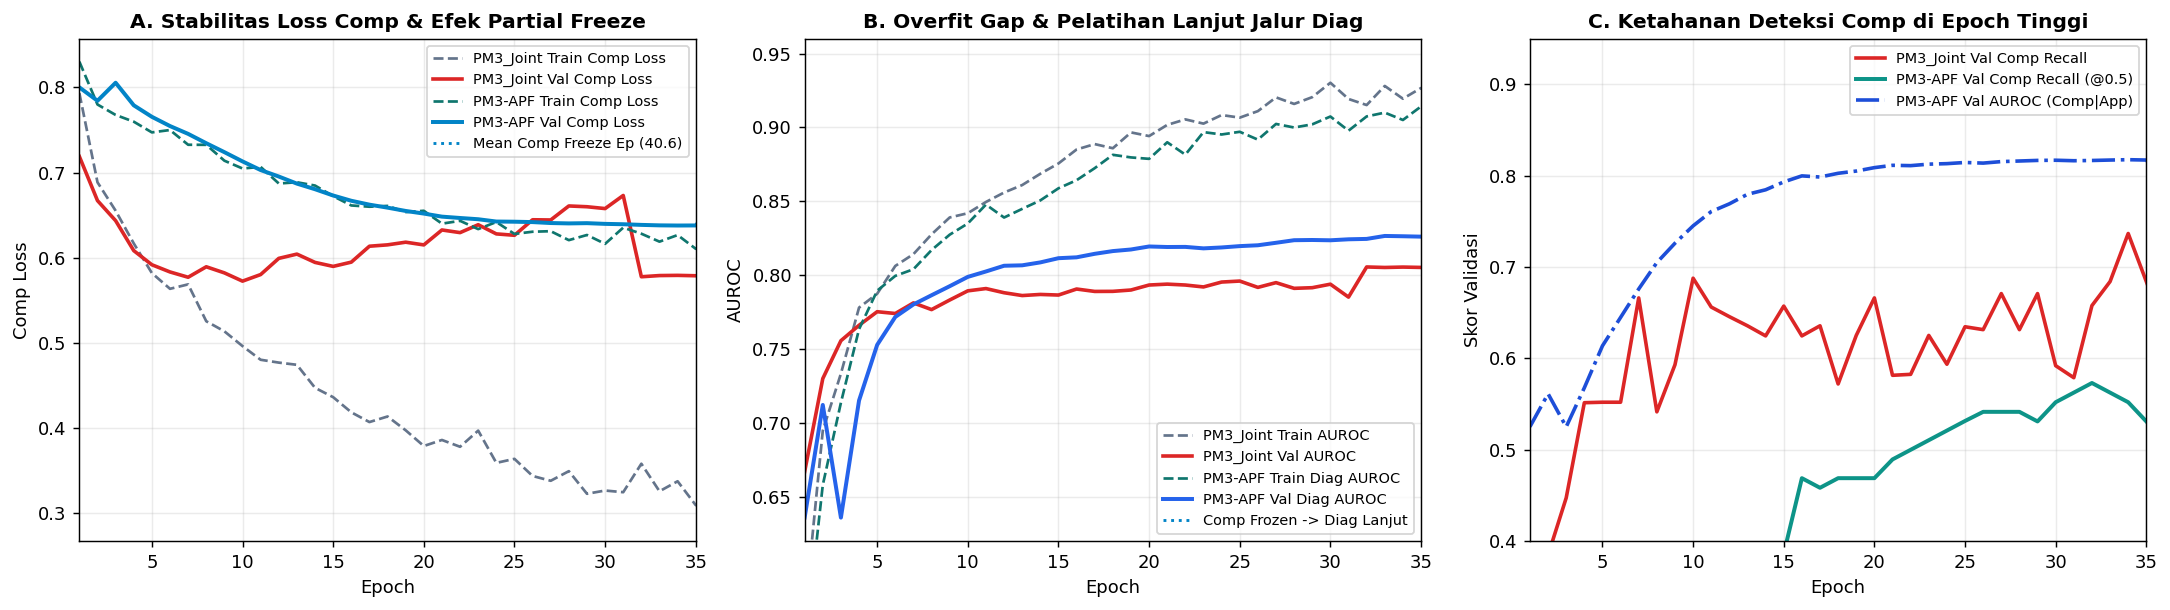

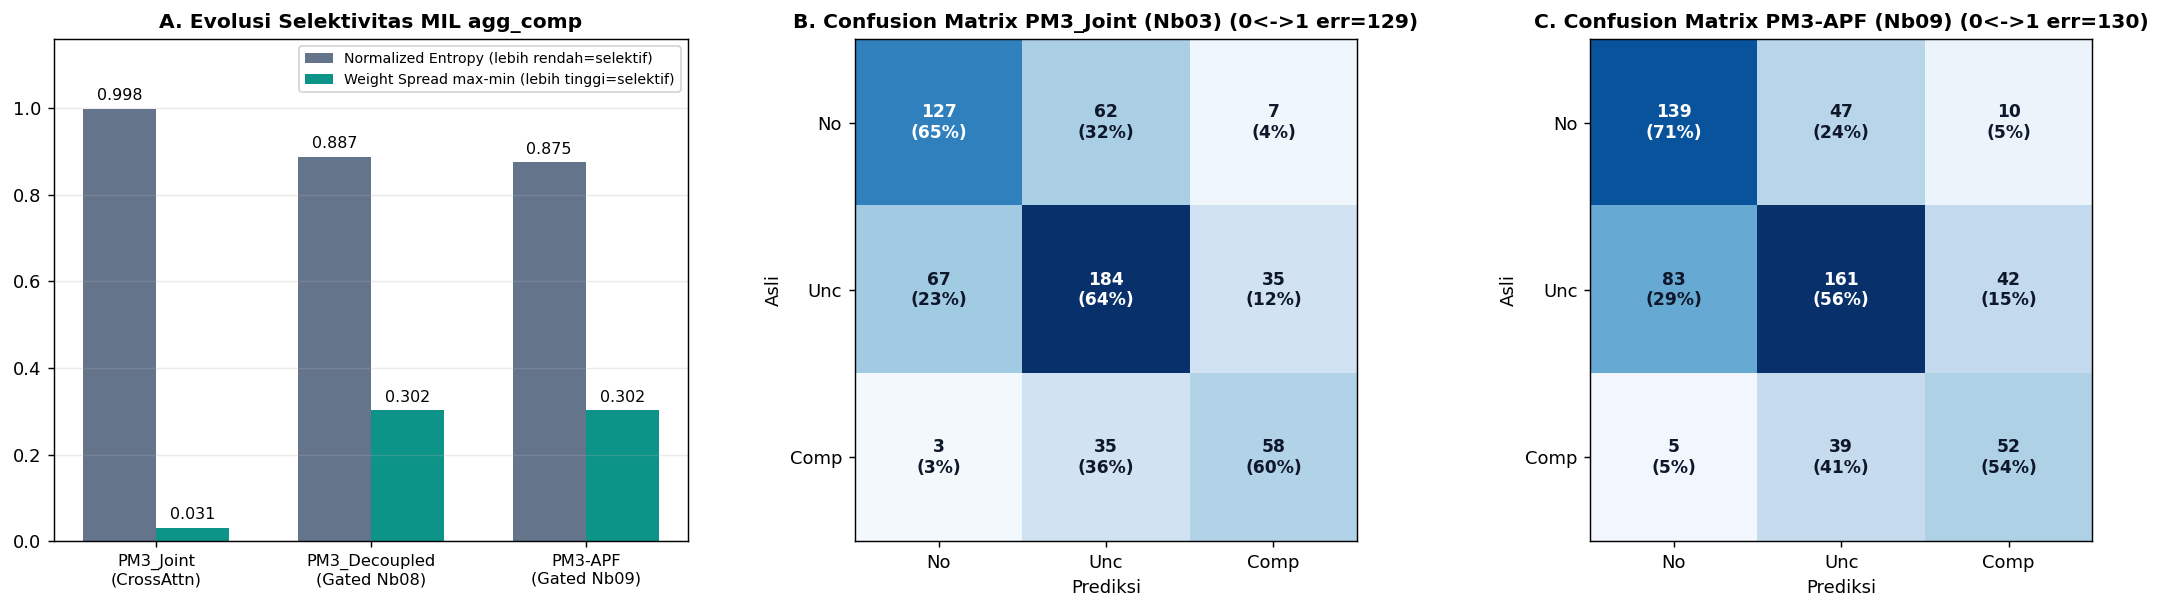

In [6]:
# ==============================================================================
# Cell 6: Visualisasi Audit PM3-APF Dual-Stage7
# ==============================================================================
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11.2, "axes.titleweight": "bold"})

fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.8))

# Panel A: Comp Loss Train vs Val (showing lock after Partial Freeze)
ax = axes[0]
ax.plot(j_hist.groupby("epoch")["train_loss_comp"].mean(), "--", color="#64748B", label="PM3_Joint Train Comp Loss")
ax.plot(j_hist.groupby("epoch")["val_loss_comp"].mean(), "-", lw=2.0, color="#DC2626", label="PM3_Joint Val Comp Loss")
ax.plot(hist_all.groupby("epoch")["train_loss_comp"].mean(), "--", color="#0F766E", label="PM3-APF Train Comp Loss")
ax.plot(hist_all.groupby("epoch")["val_loss_comp"].mean(), "-", lw=2.2, color="#0284C7", label="PM3-APF Val Comp Loss")
ax.axvline(fold_df["comp_freeze_ep"].mean(), color="#0284C7", ls=":", lw=1.6, label=f"Mean Comp Freeze Ep ({fold_df['comp_freeze_ep'].mean():.1f})")
ax.set_title("A. Stabilitas Loss Comp & Efek Partial Freeze")
ax.set_xlabel("Epoch")
ax.set_ylabel("Comp Loss")
ax.set_xlim(1, 35)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Panel B: Diag AUROC Train vs Val (showing reduced overfit + Diag fine-tuning after Comp freezes)
ax = axes[1]
ax.plot(j_hist.groupby("epoch")["train_primary_auroc"].mean(), "--", color="#64748B", label="PM3_Joint Train AUROC")
ax.plot(j_hist.groupby("epoch")["val_primary_auroc"].mean(), "-", lw=2.0, color="#DC2626", label="PM3_Joint Val AUROC")
ax.plot(hist_all.groupby("epoch")["train_auroc_diag"].mean(), "--", color="#0F766E", label="PM3-APF Train Diag AUROC")
ax.plot(hist_all.groupby("epoch")["val_auroc_diag"].mean(), "-", lw=2.2, color="#2563EB", label="PM3-APF Val Diag AUROC")
ax.axvline(fold_df["comp_freeze_ep"].mean(), color="#0284C7", ls=":", lw=1.6, label="Comp Frozen -> Diag Lanjut")
ax.set_title("B. Overfit Gap & Pelatihan Lanjut Jalur Diag")
ax.set_xlabel("Epoch")
ax.set_ylabel("AUROC")
ax.set_xlim(1, 35)
ax.set_ylim(0.62, 0.96)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Panel C: Comp Recall across epochs (Joint vs APF)
ax = axes[2]
ax.plot(j_hist.groupby("epoch")["val_complication_recall"].mean(), "-", lw=2.0, color="#DC2626", label="PM3_Joint Val Comp Recall")
ax.plot(hist_all.groupby("epoch")["val_comp_rec_3class_05"].mean(), "-", lw=2.2, color="#0D9488", label="PM3-APF Val Comp Recall (@0.5)")
ax.plot(hist_all.groupby("epoch")["val_auroc_comp_app"].mean(), "-.", lw=2.0, color="#1D4ED8", label="PM3-APF Val AUROC (Comp|App)")
ax.set_title("C. Ketahanan Deteksi Comp di Epoch Tinggi")
ax.set_xlabel("Epoch")
ax.set_ylabel("Skor Validasi")
ax.set_xlim(1, 35)
ax.set_ylim(0.40, 0.95)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

plt.tight_layout()
f1_p = OUT_DIR / "09_apf_overfit_and_freeze_curves.png"
fig.savefig(f1_p, dpi=180, bbox_inches="tight")
plt.show()

# Figure 2: Gated MIL Selectivity & 3-Class Confusion Matrix Comparison
fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.8))
ax = axes[0]
models_bar = ["PM3_Joint\n(CrossAttn)", "PM3_Decoupled\n(Gated Nb08)", "PM3-APF\n(Gated Nb09)"]
ents = [float(joint_mil_b["ent_norm_comp"]), 0.8874, float(fold_df["ent_norm_comp"].mean())]
sprs = [float(joint_mil_b["spread_comp"]), 0.3022, float(fold_df["spread_comp"].mean())]
x = np.arange(3)
w = 0.34
b1 = ax.bar(x - w / 2, ents, w, color="#64748B", label="Normalized Entropy (lebih rendah=selektif)")
b2 = ax.bar(x + w / 2, sprs, w, color="#0D9488", label="Weight Spread max-min (lebih tinggi=selektif)")
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f"{bar.get_height():.3f}", ha="center", fontsize=8.8)
ax.set_xticks(x)
ax.set_xticklabels(models_bar, fontsize=9)
ax.set_ylim(0, 1.16)
ax.set_title("A. Evolusi Selektivitas MIL agg_comp")
ax.grid(axis="y", alpha=0.25)
ax.legend(fontsize=7.8)

for i_cm, (ttl, dfm) in enumerate([
    ("B. Confusion Matrix PM3_Joint (Nb03)", joint_oof),
    ("C. Confusion Matrix PM3-APF (Nb09)", apf_oof),
]):
    ax = axes[i_cm + 1]
    cm = confusion_matrix(dfm["label"], dfm["pred_calibrated"], labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(100, cm.max()))
    for r in range(3):
        for c in range(3):
            col = "white" if cm[r, c] > cm.max() * 0.55 else "#0F172A"
            ax.text(c, r, f"{cm[r, c]}\n({cm[r, c]/cm[r].sum():.0%})", ha="center", va="center", color=col, fontsize=9.5, fontweight="bold")
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
    ax.set_xticklabels(["No", "Unc", "Comp"])
    ax.set_yticklabels(["No", "Unc", "Comp"])
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Asli")
    ax.set_title(f"{ttl} (0<->1 err={cm[0,1]+cm[1,0]})")

plt.tight_layout()
f2_p = OUT_DIR / "09_apf_mil_and_confusion.png"
fig.savefig(f2_p, dpi=180, bbox_inches="tight")
plt.show()
print("Saved plots:", f1_p, f2_p)
